# Milestone 1: NYC Housing and Transportation

## 1. Dataset Overview and Feasibility Check

### Housing & Development: Affordable Housing Production by Building (catalog H2)
- ID: `hg8x-zxpr`
- Link: https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr
- Size: 9,551 rows x 41 columns (downloaded 8 Nov 2026)
- Geographic attributes: borough, postcode, latitude, longitude, community_board, council_district, census_tract, NTA
- Temporal attributes: project_start_date, project_completion_date, building_completion_date (completions 2014-2026)
- Known issues: 20.5% of rows missing postcode and latitude/longitude; 17.4% missing building_completion_date; income-tier and bedroom unit columns mostly NaN; borough in Title Case

### Transportation: Motor Vehicle Collisions - Crashes (outside the catalog)
- ID: `h9gi-nx95`
- Link: https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95
- Size: 1,114,623 rows x 29 columns since 2018-01-01 (downloaded 8 Nov 2026). Each row is one police-reported crash.
- Geographic attributes: borough, zip_code, latitude, longitude, street names
- Temporal attributes: crash_date, crash_time
- Known issues: 32.4% of crashes missing zip_code; contributing-factor and vehicle-type columns mostly NaN beyond the first vehicle; coordinates missing in a small share of rows

### Why these datasets
We wanted to see whether the places where New York is building affordable housing are also places where streets are getting more or less dangerous. The housing file records when each building was finished and in which ZIP code, and the crash file records when and where every police-reported crash happened, so both can be lined up by ZIP code and year. The two datasets are very different in size (about 9,500 buildings against more than a million crashes), so instead of matching rows one by one we count things per ZIP per year and compare those totals. However, some housing buildings are confidential and have no location, and many crashes have no ZIP, so we are careful about what the comparison can and cannot tell us.

### Why not catalog T4 (SIRTA)
SIRTA has 13,754 rows (23 columns) covering only 2022-2026, and 41.3% of rows have no ZIP. Spread over ~200 ZIPs and several years it leaves too few crashes per ZIP-year.

### Feasibility check (outside-catalog dataset)
- Rows/columns: see above (both exceed the 9-column minimum)
- Shared integration attributes: zip_code/postcode, borough, year
- Integration level: ZIP code x year (borough x year as fallback), aggregated, not row-level
- Large-data handling: crashes downloaded through the NYC Open Data API with a date filter and column selection in 100,000-row chunks
- Missing ZIPs: recovered from latitude/longitude where available (see cleaning section)

## 5. Housing verification: independent check of `housing_clean.csv` against the raw download

The cleaned housing file was rebuilt from the raw dataset and compared field by field: dropped rows (and why), ZIP, borough, completion year, construction type, every income tier, and the `affordable_units` definition against `all_counted_units`. Results are saved in `housing_audit.csv`.

## 6. Transport cleaning: `transport_clean.csv`

Crash-level cleaning on the ZIP-recovered data: duplicate `collision_id`, date window (2018-2025), hour from `crash_time`, coordinates outside NYC set to missing, standard column names, negative or missing counts dropped (a 0 would invent "no injuries"), injury outliers flagged by a domain rule instead of IQR (the counts are zero-inflated, so IQR would flag every injury), borough uppercase with 5 valid values, contributing-factor spellings checked (56 categories before and after, so no typos or case variants needed merging), and a random sample stratified by year (about 200k rows). **Exact ZIP x year totals always use all crashes, never this sample.** Only vehicle 1's contributing factor was downloaded, so `top_contributing_factor` is that first-listed factor.

## 7. `crashes_enriched.csv`

`transport_clean` plus the `housing_group` of each crash's ZIP. A crash with no ZIP is labelled "No ZIP" (unknown), which is different from "None" (a known ZIP with no completed housing in 2018-2025).

## Exploratory data analysis (EDA): housing
Statistics and charts of the raw housing download before any cleaning: size, missing values, duplicates, building sizes, completion years, and units by borough and construction type.

### Housing EDA: findings

- The raw table has 9,551 buildings and 41 columns. There are no fully duplicated rows, but 124 `building_id` values appear more than once.
- Most buildings are small: the median is 12 units, the middle 50% have 3 to 45 units, and 1,820 or so have a single unit. A few very large buildings (up to 1,320 units) skew the distribution to the right, so the unit charts use a log scale.
- Many columns are mostly empty. The bedroom columns are 93% to 99.7% missing (`_4_br` through `_6_br` and `unknown_br`). The income-tier columns are missing for 42% (low income) to 86% (other income) of buildings. These are empty because a building has no units in that tier, not because the data is broken, so they are filled with 0 later.
- Buildings completed per year peak in 2019 (862) and 2017 (830). 2020 drops to 419, and 2026 (474) is only a partial year.
- Brooklyn has the most buildings (3,649) and units, mostly new construction. Manhattan's units are mostly preservation. Staten Island has only 445 buildings.
- New construction (4,766 buildings) and preservation (4,785) are almost evenly split.

In [1]:
import pandas as pd
from urllib.parse import urlencode

# Dataset IDs (the "ISBN" of each dataset on NYC Open Data)
HOUSING_ID = "hg8x-zxpr"   # Affordable Housing Production by Building (catalog H2)
CRASH_ID   = "h9gi-nx95"   # Motor Vehicle Collisions - Crashes (outside the catalog)
SIRTA_ID   = "xeqp-qz8h"   # SIRTA serious-injury crashes (catalog T4)

def load_dataset(dataset_id, params=None):
    """Download a dataset from NYC Open Data as a DataFrame.
    params = optional SoQL filters (e.g. $limit, $where)."""
    url = f"https://data.cityofnewyork.us/resource/{dataset_id}.csv"
    if params:
        url += "?" + urlencode(params)
    return pd.read_csv(url, low_memory=False)

# Housing and SIRTA are small enough to download fully
df_housing = load_dataset(HOUSING_ID, {"$limit": 100000})
df_sirta   = load_dataset(SIRTA_ID,   {"$limit": 100000})

# Crashes are huge, so we only take a filtered sample (2018 onward)
crash_filter = "crash_date >= '2018-01-01T00:00:00'"
df_crash = load_dataset(CRASH_ID, {"$limit": 50000, "$where": crash_filter, "$order": ":id"})

# How many crash rows exist in total since 2018?
total_crashes = load_dataset(CRASH_ID, {"$select": "count(*)", "$where": crash_filter})
print("Total crash rows since 2018:", total_crashes.iloc[0, 0])

def quick_look(name, df):
    """Print size, columns, and the most-missing columns of a DataFrame."""
    print("=" * 60)
    print(name, "| rows:", len(df), "| columns:", df.shape[1])
    print(df.columns.tolist())
    print("\nTop 8 columns by % missing:")
    print((df.isna().mean() * 100).round(1).sort_values(ascending=False).head(8))
    display(df.head(3))

quick_look("HOUSING (H2)", df_housing)
quick_look("CRASHES (h9gi-nx95, sample)", df_crash)
quick_look("SIRTA (T4)", df_sirta)

Total crash rows since 2018: 1115397
HOUSING (H2) | rows: 9551 | columns: 41
['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']

Top 8 columns by % missing:
_6_br_units                   99.7
_5_br_units                   99.2
_4_br_units               

,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,...,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25


CRASHES (h9gi-nx95, sample) | rows: 50000 | columns: 29
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_street_name', 'off_street_name', 'cross_street_name', 'number_of_persons_injured', 'number_of_persons_killed', 'number_of_pedestrians_injured', 'number_of_pedestrians_killed', 'number_of_cyclist_injured', 'number_of_cyclist_killed', 'number_of_motorist_injured', 'number_of_motorist_killed', 'contributing_factor_vehicle_1', 'contributing_factor_vehicle_2', 'contributing_factor_vehicle_3', 'contributing_factor_vehicle_4', 'contributing_factor_vehicle_5', 'collision_id', 'vehicle_type_code1', 'vehicle_type_code2', 'vehicle_type_code_3', 'vehicle_type_code_4', 'vehicle_type_code_5']

Top 8 columns by % missing:
vehicle_type_code_5              99.6
contributing_factor_vehicle_5    99.6
vehicle_type_code_4              98.5
contributing_factor_vehicle_4    98.4
vehicle_type_code_3              94.2
contributing_factor_vehicle_3    93.8
off_stre

,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,...,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,2023-10-16T00:00:00.000,09:24,BROOKLYN,11217.0,40.677715,-73.97326,"\n, \n(40.677715, -73.97326)",PARK PLACE,NaN,7 AVENUE,...,NaN,NaN,NaN,NaN,98ca2cc497d18d811ae7b45af6b2879e,NaN,NaN,NaN,NaN,NaN
1,2024-11-01T00:00:00.000,15:43,BROOKLYN,11229.0,40.615364,-73.94574,"\n, \n(40.615364, -73.94574)",E 29 ST,NaN,KINGS HWY,...,NaN,NaN,NaN,NaN,7ed37fbd2f53bd38bceaa87f3202dd1f,NaN,NaN,NaN,NaN,NaN
2,2026-03-01T00:00:00.000,01:15,MANHATTAN,10033.0,40.847870,-73.93640,"\n, \n(40.84787, -73.9364)",W 178 ST,NaN,WADSWORTH AVE,...,NaN,NaN,NaN,NaN,42f3d7b080fad88afebdc5e146181749,NaN,NaN,NaN,NaN,NaN


SIRTA (T4) | rows: 13754 | columns: 23
['open_data_crash_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020_', 'neighborhood_tabulation_area_nta_2020_']

Top 8 columns by % missing:
highway_reference_marker                  92.4
address                                   81.3
bin                                       79.7
bbl                                       79.7
neighborhood_tabulation_area_nta_2020_    71.9
council_district                          71.9
community_board                           71.9
census_tract_2020_                        71.9
dtype: float64


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201


## Housing cleaning (pre-integration)

Cleaning of the raw housing table. The result is saved as `housing_clean.csv`, which the rest of the notebook reads.

- **Duplicates:** `building_id` identifies one building. The first row of each repeated id is kept (rows with no id are kept).
- **Formats:** borough in upper case, ZIP as a 5-character string, completion date parsed into `completion_date` and `completion_year`, one `construction_type` column.
- **Missing values:** an empty income tier means no units in that tier, so it becomes 0. Coordinates outside NYC would become missing. A missing ZIP is filled from the other buildings of the same project only when they all share one ZIP.
- **Derived columns:** `affordable_units` is every income tier except `other_income_units`. `units_outlier` flags very large buildings with the IQR rule; they are kept because they are real buildings.

raw rows                                    9551
raw total units                           445588
rows dropped (repeated building_id)          124
units in the dropped rows                  13213
coordinates outside NYC set to missing         0
ZIPs filled from the project                   0
buildings flagged as unit outliers          1155
clean rows                                  9427
clean total units                         432375


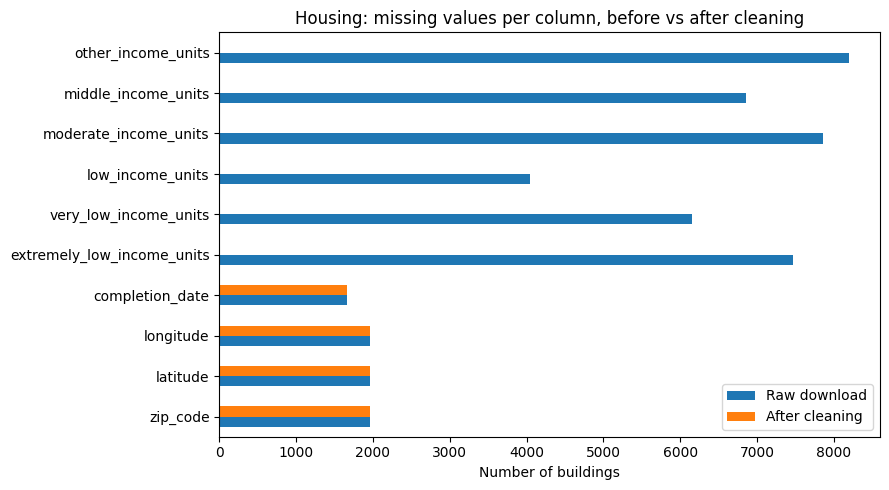


Rows: this cell 9427 | repo file 9427
  project_id: 0 different
  building_id: 0 different
  borough: 0 different
  zip_code: 0 different
  latitude: 0 different
  longitude: 0 different
  completion_date: 0 different
  completion_year: 0 different
  construction_type: 0 different
  total_units: 0 different
  affordable_units: 0 different
  extremely_low_income_units: 0 different
  very_low_income_units: 0 different
  low_income_units: 0 different
  moderate_income_units: 0 different
  middle_income_units: 0 different
  other_income_units: 0 different
  zip_filled_from_project: 1 different
  units_outlier: 0 different


In [2]:
import numpy as np
import matplotlib.pyplot as plt

income_cols = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
               "moderate_income_units", "middle_income_units", "other_income_units"]
h = df_housing.copy()
housing_log = {"raw rows": len(h), "raw total units": int(h["total_units"].sum())}

# 1. Duplicates: building_id identifies a building. Keep the first row of each repeated id (missing ids are kept).
repeated = h["building_id"].notna() & h["building_id"].duplicated(keep="first")
housing_log["rows dropped (repeated building_id)"] = int(repeated.sum())
housing_log["units in the dropped rows"] = int(h.loc[repeated, "total_units"].sum())
h = h[~repeated].copy()

# 2. Formats: upper-case borough, ZIP as a 5-character string, parsed dates, one construction-type column
h["borough"] = h["borough"].astype("string").str.upper().str.strip()
h["zip_code"] = pd.to_numeric(h["postcode"], errors="coerce").round().astype("Int64").astype("string").str.zfill(5)
dates = pd.to_datetime(h["building_completion_date"], errors="coerce")
h["completion_date"] = dates.dt.strftime("%Y-%m-%d")
h["completion_year"] = dates.dt.year.astype("Int64")
h["construction_type"] = h["reporting_construction_type"].astype("string").str.strip()

# 3. Missing values: an empty income tier means "no units in that tier", so NaN becomes 0.
#    Coordinates outside NYC would become missing.
h[income_cols] = h[income_cols].fillna(0).astype(int)
bad_xy = ~(h["latitude"].between(40.4, 41.0) & h["longitude"].between(-74.3, -73.6)) & h["latitude"].notna()
housing_log["coordinates outside NYC set to missing"] = int(bad_xy.sum())
h.loc[bad_xy, ["latitude", "longitude"]] = np.nan

# 4. A missing ZIP is filled from the other buildings of the same project, only when they all share one ZIP
by_project = h.dropna(subset=["zip_code"]).groupby("project_id")["zip_code"].agg(["nunique", "first"])
single_zip = by_project.loc[by_project["nunique"] == 1, "first"]
fill = h["zip_code"].isna() & h["project_id"].isin(single_zip.index)
h["zip_filled_from_project"] = fill
h.loc[fill, "zip_code"] = h.loc[fill, "project_id"].map(single_zip)
housing_log["ZIPs filled from the project"] = int(fill.sum())

# 5. Derived columns: affordable_units = every income tier except other_income_units;
#    units_outlier flags very large buildings with the IQR rule (they are kept, not removed)
h["affordable_units"] = h[income_cols[:-1]].sum(axis=1)
q1, q3 = h["total_units"].quantile([0.25, 0.75])
h["units_outlier"] = h["total_units"] > q3 + 1.5 * (q3 - q1)
housing_log["buildings flagged as unit outliers"] = int(h["units_outlier"].sum())

housing_clean = h[["project_id", "building_id", "borough", "zip_code", "latitude", "longitude",
                   "completion_date", "completion_year", "construction_type", "total_units",
                   "affordable_units"] + income_cols + ["zip_filled_from_project", "units_outlier"]
                  ].reset_index(drop=True)
housing_clean.to_csv("housing_clean.csv", index=False)
housing_log["clean rows"] = len(housing_clean)
housing_log["clean total units"] = int(housing_clean["total_units"].sum())
print(pd.Series(housing_log).to_string())

# Before / after: missing values per column (raw vs cleaned)
before = df_housing[["postcode", "latitude", "longitude", "building_completion_date"] + income_cols].isna().sum()
after = housing_clean[["zip_code", "latitude", "longitude", "completion_date"] + income_cols].isna().sum()
compare = pd.DataFrame({"Raw download": before.values, "After cleaning": after.values},
                       index=["zip_code", "latitude", "longitude", "completion_date"] + income_cols)
compare.plot.barh(figsize=(9, 5))
plt.title("Housing: missing values per column, before vs after cleaning")
plt.xlabel("Number of buildings")
plt.tight_layout()
plt.show()

# Check against the shared file in the GitHub repo (the one the website and the integration use)
REPO_FILE = "https://raw.githubusercontent.com/ziadhabashi111/nyc-housing-street-safety/main/data/housing_clean.csv"
ref = pd.read_csv(REPO_FILE, dtype={"zip_code": "string"})
sort_cols = ["project_id", "building_id", "total_units", "completion_date", "latitude"]
a = housing_clean.sort_values(sort_cols).reset_index(drop=True)
b = ref.sort_values(sort_cols).reset_index(drop=True)
print("\nRows: this cell", len(a), "| repo file", len(b))
if len(a) == len(b):
    for c in b.columns:
        x, y = a[c], b[c]
        if c not in ("borough", "zip_code", "completion_date", "construction_type"):
            x, y = pd.to_numeric(x).astype(float), pd.to_numeric(y).astype(float)   # 2019 vs 2019.0
        same = (x.astype("string") == y.astype("string")) | (x.isna() & y.isna())
        print(f"  {c}: {int((~same).sum())} different")

### Housing cleaning: results

- 124 rows were dropped because their `building_id` already appeared earlier in the table. They hold 13,213 units (3.0% of the 445,588 raw units). 9,427 buildings and 432,375 units remain.
- No coordinates were outside NYC, and no missing ZIP could be filled from another building of the same project, so ZIP and coordinates keep their original gaps (1,956 buildings without a ZIP, 1,957 without coordinates, 1,663 without a completion date).
- Empty income tiers were set to 0 because they mean "no units in that tier". The chart shows this: the missing counts for the income columns go to zero, while ZIP, coordinates and completion date stay missing because we cannot know those values.
- 1,155 buildings (12.3%) have more than 105 units and are flagged in `units_outlier`. They are real large buildings, so they are kept.
- The rebuilt table matches the shared copy of `housing_clean.csv` in every value. The only difference is one building whose `zip_filled_from_project` flag is set in the shared copy but not in this rebuild. No ZIP or other value differs.

In [3]:
import time

yearly_tables = []
for year in range(2018, 2027):
    start = time.time()
    year_filter = f"crash_date >= '{year}-01-01T00:00:00' AND crash_date < '{year + 1}-01-01T00:00:00'"
    table = load_dataset(CRASH_ID, {
        "$select": "zip_code, count(*) AS crash_count, sum(number_of_persons_injured) AS persons_injured",
        "$where": year_filter,
        "$group": "zip_code",
        "$limit": 5000,
    })
    table["crash_year"] = year
    yearly_tables.append(table)
    print(f"{year}: {len(table)} ZIP rows, {time.time() - start:.1f}s")

zip_year = pd.concat(yearly_tables, ignore_index=True)
print("\nZIP x year table shape:", zip_year.shape)
print("Crashes with missing ZIP:", zip_year.loc[zip_year["zip_code"].isna(), "crash_count"].sum(),
      "of", zip_year["crash_count"].sum())
display(zip_year.head())

2018: 217 ZIP rows, 8.4s
2019: 220 ZIP rows, 4.4s
2020: 204 ZIP rows, 3.5s
2021: 210 ZIP rows, 2.1s
2022: 211 ZIP rows, 1.6s
2023: 213 ZIP rows, 1.8s
2024: 207 ZIP rows, 3.2s
2025: 212 ZIP rows, 2.9s
2026: 208 ZIP rows, 4.1s

ZIP x year table shape: (1902, 4)
Crashes with missing ZIP: 361138 of 1115397


,zip_code,crash_count,persons_injured,crash_year
0,10000.0,65,16,2018
1,10001.0,1715,209,2018
2,10002.0,1566,319,2018
3,10003.0,940,205,2018
4,10004.0,257,40,2018


Shape: (9551, 41)

Duplicate rows: 0 | duplicate building_id values: 124

Descriptive statistics of the unit columns:


,total_units,all_counted_units,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units
count,9551.0,9522.0,2081.0,3400.0,5505.0,1694.0,2691.0,1360.0
mean,46.7,33.7,28.3,25.5,19.8,11.6,16.9,1.0
std,92.5,65.8,44.6,49.3,40.7,30.3,34.5,0.5
min,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
25%,3.0,2.0,2.0,3.0,1.0,1.0,3.0,1.0
50%,12.0,8.0,8.0,7.0,5.0,3.0,6.0,1.0
75%,45.0,30.0,37.0,21.0,19.0,8.0,15.0,1.0
max,1320.0,917.0,429.0,453.0,536.0,454.0,448.0,16.0



Buildings per borough (raw spelling):
borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445

Buildings per construction type:
reporting_construction_type
Preservation        4785
New Construction    4766


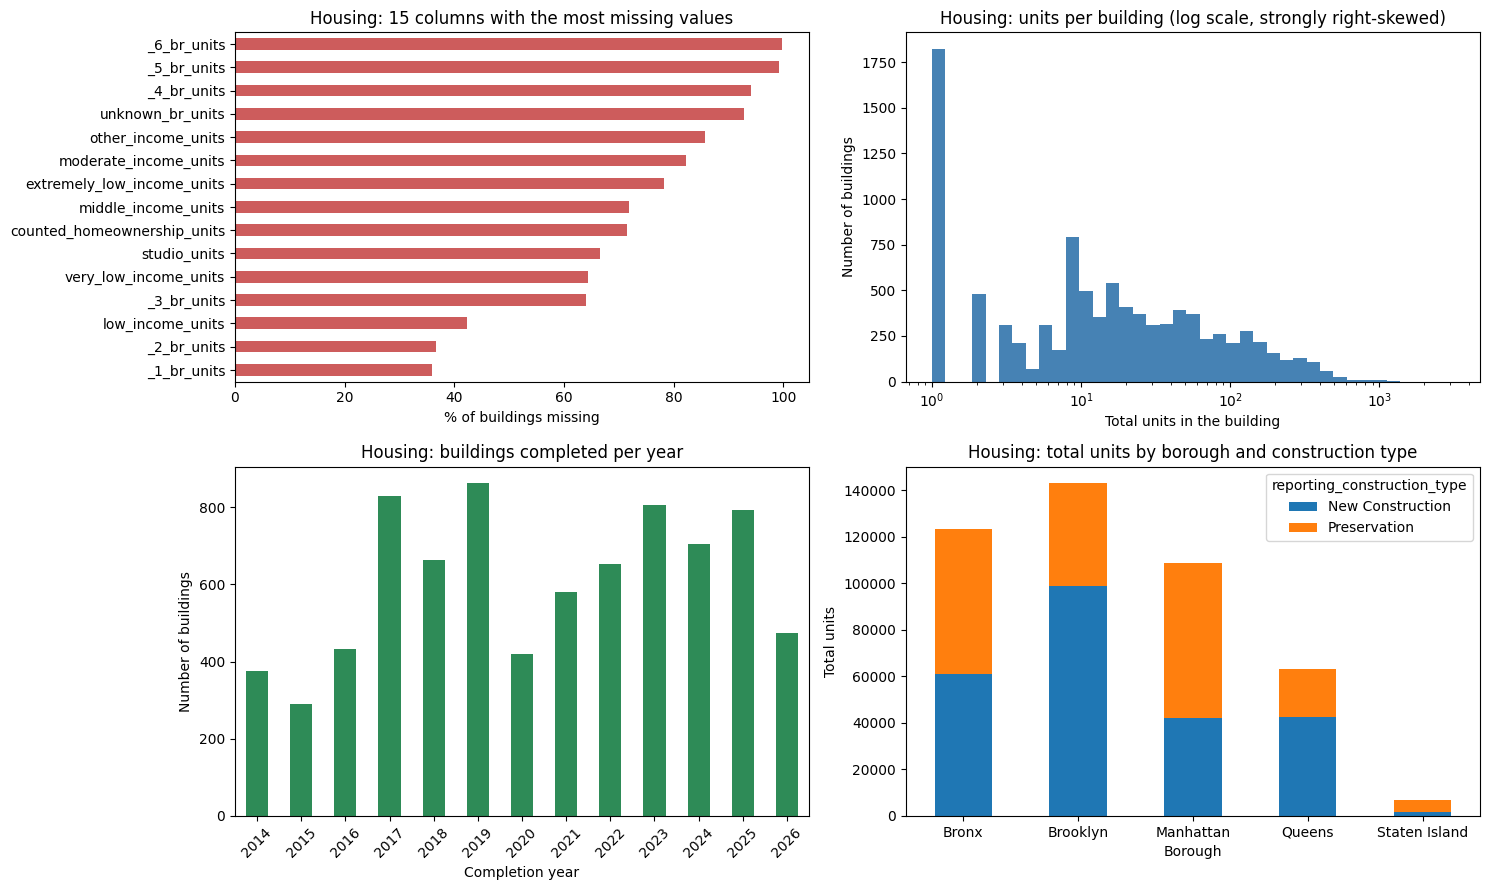

In [4]:
# ---- EDA 1: housing (raw download: df_housing) ----
import numpy as np
import matplotlib.pyplot as plt

housing_numeric = ["total_units", "all_counted_units", "extremely_low_income_units", "very_low_income_units",
                   "low_income_units", "moderate_income_units", "middle_income_units", "other_income_units"]

print("Shape:", df_housing.shape)
print("\nDuplicate rows:", int(df_housing.duplicated().sum()),
      "| duplicate building_id values:", int(df_housing["building_id"].dropna().duplicated().sum()))
print("\nDescriptive statistics of the unit columns:")
display(df_housing[housing_numeric].describe().round(1))

print("\nBuildings per borough (raw spelling):")
print(df_housing["borough"].value_counts(dropna=False).to_string())
print("\nBuildings per construction type:")
print(df_housing["reporting_construction_type"].value_counts(dropna=False).to_string())

completion_year_raw = pd.to_datetime(df_housing["building_completion_date"], errors="coerce").dt.year

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# 1. Which columns are mostly empty?
(df_housing.isna().mean() * 100).sort_values(ascending=False).head(15).sort_values().plot.barh(ax=axes[0, 0], color="indianred")
axes[0, 0].set_title("Housing: 15 columns with the most missing values")
axes[0, 0].set_xlabel("% of buildings missing")

# 2. Building size is very skewed -> log scale shows the shape
axes[0, 1].hist(df_housing["total_units"].dropna().clip(lower=1), bins=np.logspace(0, 3.5, 40), color="steelblue")
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Housing: units per building (log scale, strongly right-skewed)")
axes[0, 1].set_xlabel("Total units in the building"); axes[0, 1].set_ylabel("Number of buildings")

# 3. When were buildings completed? (2026 is a partial year)
completion_year_raw.value_counts().sort_index().plot.bar(ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Housing: buildings completed per year")
axes[1, 0].set_xlabel("Completion year"); axes[1, 0].set_ylabel("Number of buildings")
axes[1, 0].set_xticklabels([str(int(y)) for y in sorted(completion_year_raw.dropna().unique())], rotation=45)

# 4. Where are the units, and what kind of project?
(df_housing.groupby(["borough", "reporting_construction_type"])["total_units"].sum()
           .unstack().plot.bar(stacked=True, ax=axes[1, 1]))
axes[1, 1].set_title("Housing: total units by borough and construction type")
axes[1, 1].set_xlabel("Borough"); axes[1, 1].set_ylabel("Total units")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [5]:
import time

CHUNK = 100_000
select_cols = ("crash_date,crash_time,borough,zip_code,latitude,longitude,"
               "number_of_persons_injured,number_of_persons_killed,"
               "number_of_pedestrians_injured,number_of_cyclist_injured,"
               "number_of_motorist_injured,contributing_factor_vehicle_1,collision_id")
where = "crash_date >= '2018-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'"

chunks, offset = [], 0
while True:
    t = time.time()
    part = load_dataset(CRASH_ID, {"$select": select_cols, "$where": where,
                                   "$order": ":id", "$limit": CHUNK, "$offset": offset})
    chunks.append(part)
    print(f"offset {offset}: {len(part)} rows, {time.time() - t:.1f}s")
    if len(part) < CHUNK:
        break
    offset += CHUNK

df_crash_full = pd.concat(chunks, ignore_index=True)
print(df_crash_full.shape)
df_crash_full.to_csv("/content/crashes_full_raw.csv", index=False)

offset 0: 100000 rows, 15.8s
offset 100000: 100000 rows, 8.4s
offset 200000: 100000 rows, 21.5s
offset 300000: 100000 rows, 17.3s
offset 400000: 100000 rows, 13.0s
offset 500000: 100000 rows, 25.3s
offset 600000: 100000 rows, 22.8s
offset 700000: 100000 rows, 24.0s
offset 800000: 100000 rows, 10.6s
offset 900000: 100000 rows, 48.9s
offset 1000000: 43903 rows, 15.0s
(1043903, 13)


## Exploratory data analysis (EDA): crashes

Shape: (1043903, 15)
Duplicate collision_id values: 0

Descriptive statistics of the injury counts:


,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_cyclist_injured,number_of_motorist_injured
count,1043897.00,1043889.00,1043903.00,1043903.00,1043903.00
mean,0.41,0.00,0.07,0.04,0.29
std,0.77,0.05,0.27,0.20,0.73
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00
75%,1.00,0.00,0.00,0.00,0.00
max,40.00,5.00,19.00,3.00,40.00



Missing values (%):
zip_code                         32.9
borough                          31.9
latitude                          7.1
longitude                         7.1
contributing_factor_vehicle_1     0.5
crash_time                        0.0
crash_date                        0.0
number_of_persons_injured         0.0
number_of_persons_killed          0.0
number_of_cyclist_injured         0.0
number_of_pedestrians_injured     0.0
number_of_motorist_injured        0.0
collision_id                      0.0
year                              0.0
hour                              0.0


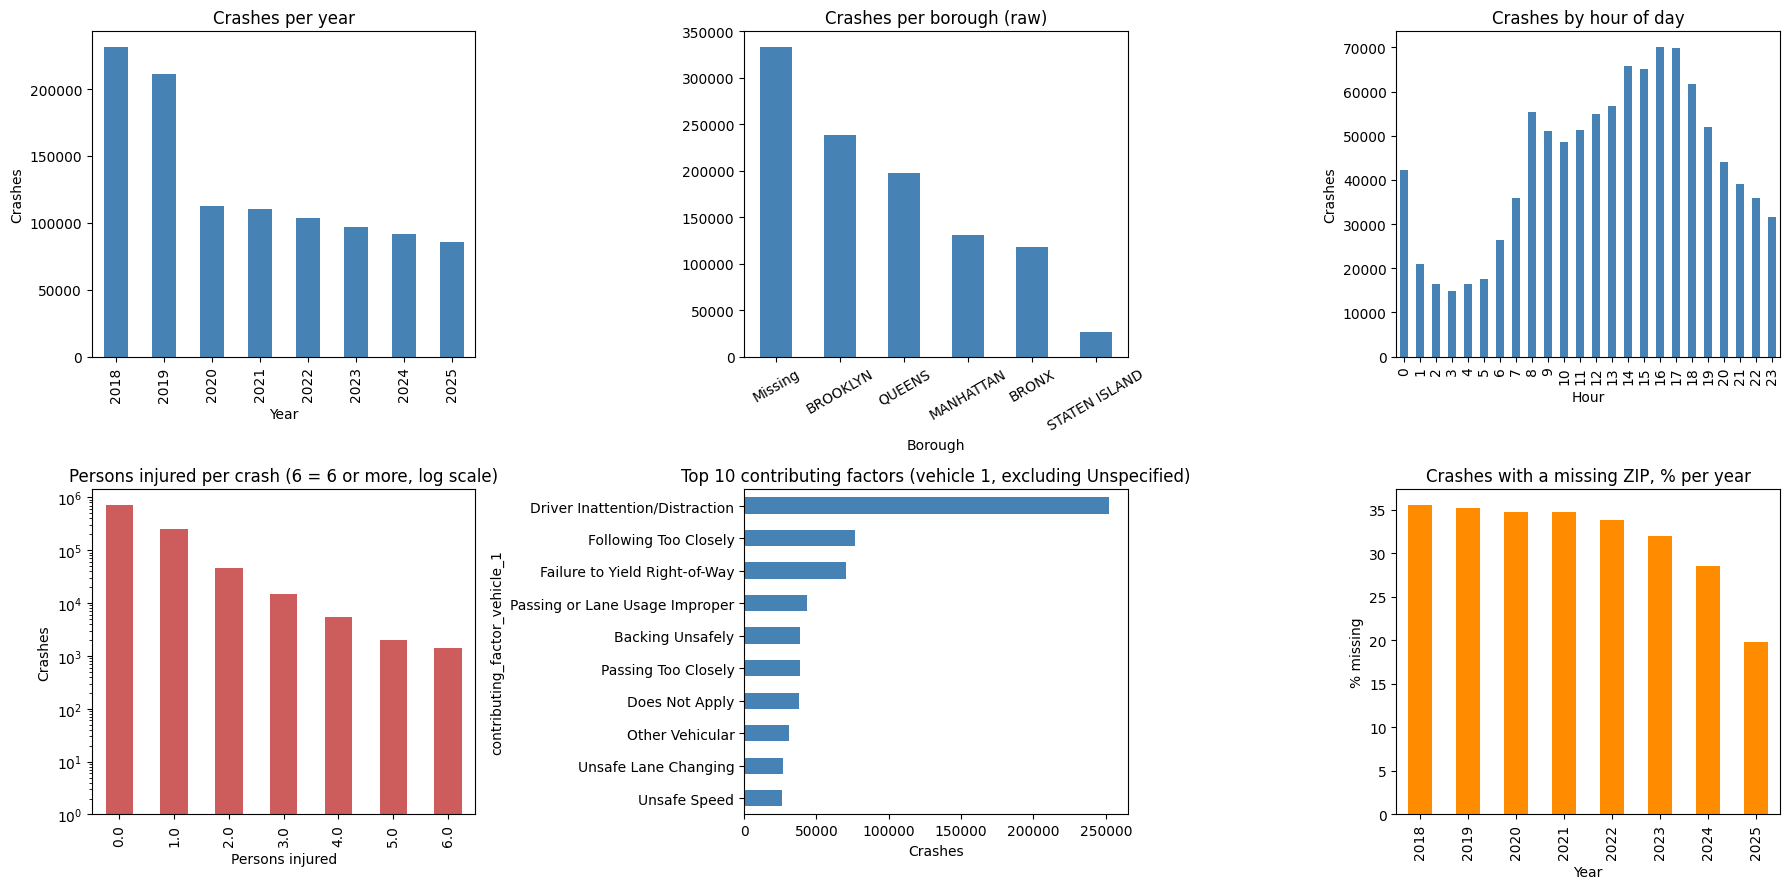

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [6]:
import numpy as np
import matplotlib.pyplot as plt

ce = df_crash_full.copy()
ce["crash_date"] = pd.to_datetime(ce["crash_date"], errors="coerce")
ce["year"] = ce["crash_date"].dt.year
ce["hour"] = pd.to_numeric(ce["crash_time"].astype("string").str.split(":").str[0], errors="coerce")

print("Shape:", ce.shape)
print("Duplicate collision_id values:", int(ce["collision_id"].duplicated().sum()))
count_cols = ["number_of_persons_injured", "number_of_persons_killed", "number_of_pedestrians_injured",
              "number_of_cyclist_injured", "number_of_motorist_injured"]
print("\nDescriptive statistics of the injury counts:")
display(ce[count_cols].describe().round(2))
print("\nMissing values (%):")
print((ce.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

ce["year"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Crashes per year")
axes[0, 0].set_xlabel("Year"); axes[0, 0].set_ylabel("Crashes")

ce["borough"].fillna("Missing").value_counts().plot.bar(ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Crashes per borough (raw)")
axes[0, 1].set_xlabel("Borough"); axes[0, 1].tick_params(axis="x", rotation=30)

ce["hour"].value_counts().sort_index().plot.bar(ax=axes[0, 2], color="steelblue")
axes[0, 2].set_title("Crashes by hour of day")
axes[0, 2].set_xlabel("Hour"); axes[0, 2].set_ylabel("Crashes")

ce["number_of_persons_injured"].clip(upper=6).value_counts().sort_index().plot.bar(
    ax=axes[1, 0], color="indianred", log=True)
axes[1, 0].set_title("Persons injured per crash (6 = 6 or more, log scale)")
axes[1, 0].set_xlabel("Persons injured"); axes[1, 0].set_ylabel("Crashes")

factors = ce["contributing_factor_vehicle_1"].value_counts()
factors = factors.drop("Unspecified", errors="ignore").head(10).sort_values()
factors.plot.barh(ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Top 10 contributing factors (vehicle 1, excluding Unspecified)")
axes[1, 1].set_xlabel("Crashes")

ce.groupby("year")["zip_code"].apply(lambda s: s.isna().mean() * 100).plot.bar(ax=axes[1, 2], color="darkorange")
axes[1, 2].set_title("Crashes with a missing ZIP, % per year")
axes[1, 2].set_xlabel("Year"); axes[1, 2].set_ylabel("% missing")

plt.tight_layout()
plt.show()

### Crash EDA: findings

- The download holds 1,043,903 crashes from 2018 to 2025, with no repeated `collision_id`.
- Recorded crashes fall from about 230,000 in 2018 and 210,000 in 2019 to about 112,000 in 2020, then keep sliding to about 86,000 in 2025.
- About a third of crashes have no ZIP (32.9%) and 31.9% have no borough. 7.1% have no coordinates, and only 0.5% have no contributing factor. The share of crashes without a ZIP falls from about 35% in 2018 to about 20% in 2025, so ZIP-level counts are less complete in the early years.
- Of the crashes with a borough, Brooklyn has the most (about 239,000) and Staten Island the fewest (about 27,000).
- Crashes follow the working day: fewest around 3 am, rising through the morning and peaking at 4 pm and 5 pm (about 70,000 each).
- Injuries are zero-inflated: roughly 7 in 10 crashes injure nobody, and each extra injured person is much rarer, with a long tail of crashes that injure 6 or more. This is why the injury charts use a log scale.
- Driver inattention/distraction is by far the most common stated factor (about 250,000 crashes), ahead of following too closely and failing to yield. "Does Not Apply" is a placeholder value, not a cause, and "Unspecified" is also very common, so it is left out of the chart.

## 2. Crash data: ZIP standardization and recovery (full 2018-2025 download)

All 1,043,903 crashes from 2018-2025 were downloaded in 100,000-row chunks with only the columns we need.

- ZIP codes were converted to 5-character strings. ZIPs outside NYC ranges, and the placeholder `10000`, were set to missing.
- About 343,941 crashes (33.0%) had no valid ZIP. We tried dropping them, but that would remove a third of the data and bias the ZIP-level counts.
- Instead, each crash with coordinates inside NYC but no ZIP took the ZIP of the nearest crash with a known ZIP, using a BallTree with haversine distance and a maximum distance of 200 m. 266,590 ZIPs were recovered and flagged in `zip_recovered`.
- 77,351 crashes (7.4%) still have no ZIP. They are excluded from ZIP-level totals but kept in borough-level totals.
- Missing boroughs were filled from the most common borough of the crash's ZIP.
- Limitation: nearest-neighbour matching can assign the wrong ZIP for crashes close to a ZIP boundary.

In [7]:
import os
SAVE_DIRS = [d for d in ["/content", "/content/drive/MyDrive"] if os.path.isdir(d)] or ["."]
import numpy as np
from sklearn.neighbors import BallTree

df = df_crash_full.copy()
# 1. Standardize ZIP to 5-character strings; invalid NYC ZIPs become missing
NYC_ZIP_PREFIXES = {"100", "101", "102", "103", "104", "110", "111", "112", "113", "114", "116"}

def zip_to_string(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.round().astype("Int64").astype("string").str.zfill(5)

df["zip_code"] = zip_to_string(df["zip_code"])
valid_zip = df["zip_code"].str[:3].isin(NYC_ZIP_PREFIXES) & (df["zip_code"] != "10000")
df.loc[~valid_zip, "zip_code"] = pd.NA

# 2. Recover missing ZIPs from coordinates (nearest crash with a known ZIP, max 200 m)
has_coords = (df["latitude"].between(40.4, 41.0)) & (df["longitude"].between(-74.3, -73.6))
known = df["zip_code"].notna() & has_coords
to_fill = df["zip_code"].isna() & has_coords

tree = BallTree(np.radians(df.loc[known, ["latitude", "longitude"]].to_numpy()), metric="haversine")
distance, nearest = tree.query(np.radians(df.loc[to_fill, ["latitude", "longitude"]].to_numpy()), k=1)
distance_m = distance[:, 0] * 6_371_000
nearest_zip = df.loc[known, "zip_code"].to_numpy()[nearest[:, 0]]

fill_index = df.index[to_fill]
accept = distance_m <= 200
df["zip_recovered"] = False
df.loc[fill_index[accept], "zip_code"] = nearest_zip[accept]
df.loc[fill_index[accept], "zip_recovered"] = True

# 3. Fill missing borough from each ZIP's most common borough
zip_to_borough = (df.dropna(subset=["zip_code", "borough"])
                    .groupby("zip_code")["borough"].agg(lambda s: s.mode().iloc[0]))
df["borough"] = df["borough"].fillna(df["zip_code"].map(zip_to_borough))

# 4. Exact ZIP x year totals from ALL crashes
df["crash_year"] = pd.to_datetime(df["crash_date"]).dt.year
zip_year_full = (df.dropna(subset=["zip_code"])
                   .groupby(["zip_code", "crash_year"])
                   .agg(crash_count=("collision_id", "count"),
                        persons_injured=("number_of_persons_injured", "sum"),
                        persons_killed=("number_of_persons_killed", "sum"),
                        ped_injured=("number_of_pedestrians_injured", "sum"),
                        cyc_injured=("number_of_cyclist_injured", "sum"),
                        motorist_injured=("number_of_motorist_injured", "sum"))
                   .reset_index())

print("Rows:", len(df), "| ZIPs recovered:", int(df["zip_recovered"].sum()),
      "| still missing ZIP:", int(df["zip_code"].isna().sum()),
      f"({df['zip_code'].isna().mean() * 100:.1f}%)")
print("ZIP x year table:", zip_year_full.shape)
display(zip_year_full.head())

zip_year_full.to_csv("/content/zip_year_crashes_full.csv", index=False)
# (Drive copy skipped; the final data_bundle.zip contains every output)

Rows: 1043903 | ZIPs recovered: 266590 | still missing ZIP: 77351 (7.4%)
ZIP x year table: (1683, 8)


,zip_code,crash_year,crash_count,persons_injured,persons_killed,ped_injured,cyc_injured,motorist_injured
0,10001,2018,1926,235.0,1.0,84,43,108
1,10001,2019,1689,231.0,1.0,81,43,107
2,10001,2020,515,167.0,2.0,53,44,70
3,10001,2021,572,240.0,1.0,61,60,110
4,10001,2022,589,221.0,1.0,89,52,68


## 3. Integration

**Join key and granularity:** ZIP code x year (2018-2025). The datasets share no record-level key and differ hugely in size (9,427 cleaned buildings vs about 1 million crashes), so both are aggregated to ZIP x year instead of joining rows.
- **Housing input:** `housing_clean.csv` (written by the housing cleaning section above, 9,427 buildings; the other 124 of the 9,551 raw buildings, 13,213 units, were repeated building_id rows and were dropped there). affordable_units is every income tier except other_income_units, so it is lower than the raw all_counted_units in 1,332 buildings (usually by 1 unit). Buildings with both a ZIP and a completion year are grouped by ZIP and completion year (projects, total units, affordable units, new-construction vs preservation units, income-tier units). 2026 is excluded because it is a partial year (data ends 21 Aug 2026) and the crash download stops at 2025.
- **What is excluded, and why it matters:** 3,542 of 9,427 buildings (37.6%) have no ZIP or no completion year. The two gaps are very different. The 1,956 buildings without a ZIP are tiny (3,512 units, 0.8% of units), while the 1,663 buildings without a completion year hold 111,852 units (25.9%). Only 5,885 buildings (73.5% of units) can be placed in a ZIP x year, and 4,350 buildings (242,248 units, 56.0% of all units) completed in the 2018-2025 window and enter the ZIP x year table. The full breakdown is saved in `housing_excluded_summary.csv`.
- **Uneven missing ZIPs:** Staten Island buildings lack a ZIP 71.5% of the time (Queens 41.8%, Bronx 16.9%, Brooklyn 15.5%, Manhattan 5.9%), so ZIP-level results for Staten Island and Queens are the least reliable.
- **Crashes:** grouped by ZIP and crash year (crash count, persons injured and killed, pedestrian, cyclist and motorist injuries).
- **Join type:** outer join on (zip_code, year) with an indicator column, so unmatched rows stay visible. Result: 1,683 ZIP-years across 228 ZIPs (718 with both crashes and completed housing, 965 with crashes only, 0 with housing only); all 242,248 housing units and all 966,552 crashes that have a ZIP are preserved. Assertions check that total units and total crashes are identical before and after the join.
- **Fallback level:** borough x year, built from all crashes and from all buildings that have a completion year, including those without a ZIP.
- **Alternative considered:** a spatial join on latitude/longitude. Rejected because most crashes are not caused by a specific building and because ~20% of buildings have no coordinates; ZIP x year is easier to interpret.

In [8]:
import os
# Use the file written by the housing cleaning cells above; otherwise read the same file from the GitHub repo
HOUSING_CLEAN_URL = "https://raw.githubusercontent.com/ziadhabashi111/nyc-housing-street-safety/main/data/housing_clean.csv"
HOUSING_CLEAN_PATH = "housing_clean.csv" if os.path.exists("housing_clean.csv") else HOUSING_CLEAN_URL

def zip_to_string(series):
    """Any ZIP representation (10001, 10001.0, '10001') -> 5-character string; missing stays <NA>."""
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.round().astype("Int64").astype("string").str.zfill(5)

# six income tiers; affordable_units (from the cleaning step) = all tiers except other_income_units
income_cols = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
               "moderate_income_units", "middle_income_units", "other_income_units"]

housing = pd.read_csv(HOUSING_CLEAN_PATH, low_memory=False)
housing["zip_code"] = zip_to_string(housing["zip_code"])          # float 10001.0 in the CSV -> "10001"
housing["completion_year"] = housing["completion_year"].astype("Int64")
housing["borough"] = housing["borough"].str.upper().str.strip()
print(housing["construction_type"].value_counts(dropna=False))

# ---- Exclusion accounting: how much housing cannot be placed in a ZIP x year? ----
WINDOW = (2018, 2025)                       # crash data covers 2018-2025 (2026 is a partial year)
no_zip = housing["zip_code"].isna()
no_year = housing["completion_year"].isna()
in_window = housing["completion_year"].between(*WINDOW).fillna(False).astype(bool)

def count_row(label, mask):
    return {"group": label, "buildings": int(mask.sum()),
            "share_of_buildings_pct": round(100 * mask.mean(), 1),
            "total_units": int(housing.loc[mask, "total_units"].sum()),
            "share_of_units_pct": round(100 * housing.loc[mask, "total_units"].sum()
                                        / housing["total_units"].sum(), 1)}

excluded_summary = pd.DataFrame([
    count_row("All buildings in housing_clean", pd.Series(True, index=housing.index)),
    count_row("Excluded from ZIP x year: no ZIP", no_zip),
    count_row("Excluded from ZIP x year: no completion year", no_year),
    count_row("Excluded from ZIP x year: no ZIP AND no year", no_zip & no_year),
    count_row("Excluded from ZIP x year: no ZIP OR no year (total)", no_zip | no_year),
    count_row("Kept in borough x year: has year but no ZIP", no_zip & ~no_year),
    count_row("Usable for ZIP x year (ZIP and year present)", ~no_zip & ~no_year),
    count_row("...of which completed 2018-2025 (analysis window)", ~no_zip & in_window),
])
display(excluded_summary)

print("\nMissing ZIP rate by borough (the ZIP-level view is blind where this is high):")
print((housing.groupby("borough")["zip_code"].apply(lambda s: s.isna().mean() * 100)).round(1))

def add_unit_split(frame):
    """Split total_units into new-construction vs preservation units."""
    frame = frame.copy()
    is_new = frame["construction_type"].str.contains("new", case=False, na=False)
    is_pres = frame["construction_type"].str.contains("preserv", case=False, na=False)
    frame["new_units"] = frame["total_units"].where(is_new, 0)
    frame["preservation_units"] = frame["total_units"].where(is_pres, 0)
    return frame

def build_housing_zip_year(housing_df):
    """Aggregate building-level housing to ZIP x completion year (buildings need ZIP and year)."""
    usable = add_unit_split(housing_df.dropna(subset=["zip_code", "completion_year"]))
    return (usable.groupby(["zip_code", "completion_year"])
                  .agg(projects_completed=("project_id", "nunique"),
                       total_units=("total_units", "sum"),
                       affordable_units=("affordable_units", "sum"),
                       new_construction_units=("new_units", "sum"),
                       preservation_units=("preservation_units", "sum"),
                       **{c: (c, "sum") for c in income_cols})
                  .reset_index()
                  .rename(columns={"completion_year": "year"}))

housing_zip_year = build_housing_zip_year(housing)
housing_zip_year = housing_zip_year[housing_zip_year["year"].between(*WINDOW)]
print("Housing ZIP x year (2018-2025):", housing_zip_year.shape)
display(housing_zip_year.head())
housing_zip_year.to_csv("housing_zip_year.csv", index=False)
excluded_summary.to_csv("housing_excluded_summary.csv", index=False)

construction_type
New Construction    4753
Preservation        4674
Name: count, dtype: int64


,group,buildings,share_of_buildings_pct,total_units,share_of_units_pct
0,All buildings in housing_clean,9427,100.0,432375,100.0
1,Excluded from ZIP x year: no ZIP,1957,20.8,3513,0.8
2,Excluded from ZIP x year: no completion year,1663,17.6,111852,25.9
3,Excluded from ZIP x year: no ZIP AND no year,77,0.8,820,0.2
4,Excluded from ZIP x year: no ZIP OR no year (t...,3543,37.6,114545,26.5
5,Kept in borough x year: has year but no ZIP,1880,19.9,2693,0.6
6,Usable for ZIP x year (ZIP and year present),5884,62.4,317830,73.5
7,...of which completed 2018-2025 (analysis window),4349,46.1,242247,56.0



Missing ZIP rate by borough (the ZIP-level view is blind where this is high):
borough
BRONX            16.9
BROOKLYN         15.5
MANHATTAN         5.9
QUEENS           41.9
STATEN ISLAND    71.5
Name: zip_code, dtype: float64
Housing ZIP x year (2018-2025): (718, 13)


,zip_code,year,projects_completed,total_units,affordable_units,new_construction_units,preservation_units,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units
2,10001,2018,2,939,194,939,0,0,6,188,0,0,0
3,10001,2019,1,223,45,223,0,0,0,45,0,0,0
4,10001,2020,2,92,54,92,0,0,0,46,0,8,0
5,10001,2021,1,106,106,106,0,0,0,106,0,0,0
6,10001,2023,2,1418,378,1418,0,0,94,238,46,0,0


In [9]:
raw = df_housing.copy()
raw[income_cols] = raw[income_cols].fillna(0)             # NaN tier = no units in that tier
raw["zip_code"] = zip_to_string(raw["postcode"])
raw["completion_year"] = pd.to_datetime(raw["building_completion_date"], errors="coerce").dt.year.astype("Int64")
raw["borough"] = raw["borough"].astype("string").str.upper().str.strip()
five_tiers = income_cols[:-1]                              # affordable = all tiers except other_income_units
raw["affordable_rebuilt"] = raw[five_tiers].sum(axis=1)

KEY = ["project_id", "building_id", "completion_year", "total_units"]
def key_frame(frame):
    """Numeric match key; missing parts become -1 so rows with NaN building_id still match."""
    keys = pd.DataFrame({c: pd.to_numeric(frame[c], errors="coerce").fillna(-1).astype("int64")
                         for c in KEY}, index=frame.index)
    keys["dup"] = keys.groupby(KEY).cumcount()             # separate identical rows
    return keys

raw_k, clean_k = key_frame(raw), key_frame(housing)
raw_m = pd.concat([raw, raw_k.add_prefix("k_")], axis=1)
clean_m = pd.concat([housing, clean_k.add_prefix("k_")], axis=1)
kcols = ["k_" + c for c in KEY + ["dup"]]
joined = raw_m.merge(clean_m, on=kcols, how="outer", suffixes=("_raw", "_clean"), indicator=True)

only_raw = joined[joined["_merge"] == "left_only"]
only_clean = joined[joined["_merge"] == "right_only"]
both = joined[joined["_merge"] == "both"]
print(f"Raw rows: {len(raw)} | housing_clean rows: {len(housing)} | matched: {len(both)}")
print(f"Raw rows missing from housing_clean: {len(only_raw)} | rows only in housing_clean: {len(only_clean)}")

if len(only_raw):
    show = [c for c in ["project_id_raw", "building_id_raw", "borough_raw", "reporting_construction_type",
                        "total_units_raw", "building_completion_date"] if c in only_raw.columns]
    print("\nWhat the dropped raw rows look like (is there a documented reason?):")
    print("  total_units == 0:", int((only_raw["total_units_raw"] == 0).sum()),
          "| no completion year:", int(only_raw["completion_year_raw"].isna().sum()),
          "| no ZIP:", int(only_raw["zip_code_raw"].isna().sum()))
    display(only_raw[show].head(10))

def agree(a, b):
    """True where equal, treating missing == missing as agreement."""
    return (a.astype("string") == b.astype("string")) | (a.isna() & b.isna())

checks = {
    "zip_code": agree(both["zip_code_raw"], both["zip_code_clean"]),
    "borough": agree(both["borough_raw"], both["borough_clean"].astype("string").str.upper()),
    "completion_year": agree(both["completion_year_raw"], both["completion_year_clean"]),
}
type_raw = "reporting_construction_type"
if type_raw in both.columns:
    checks["construction_type (case-insensitive)"] = agree(
        both[type_raw].astype("string").str.lower(), both["construction_type"].astype("string").str.lower())
for c in income_cols:
    checks[c] = agree(both[c + "_raw"].astype("Int64"), both[c + "_clean"].astype("Int64"))
checks["affordable_units == tiers minus other"] = agree(
    both["affordable_rebuilt"].astype("Int64"), both["affordable_units"].astype("Int64"))

if "all_counted_units" in both.columns:
    counted = pd.to_numeric(both["all_counted_units"], errors="coerce")
    checks["affordable_units == all_counted_units"] = agree(counted.astype("Int64"),
                                                          both["affordable_units"].astype("Int64"))
    gap = (both["total_units_raw"] - counted).value_counts().head(5)
    print("\ntotal_units minus all_counted_units (top values):")
    print(gap.to_string())

housing_audit = pd.DataFrame({"rows_checked": len(both),
                              "mismatches": {k: int((~v).sum()) for k, v in checks.items()}})
housing_audit["mismatch_pct"] = (100 * housing_audit["mismatches"] / housing_audit["rows_checked"]).round(2)
display(housing_audit)
print("\nOther sanity checks on housing_clean:")
print("  affordable_units > total_units:", int((housing["affordable_units"] > housing["total_units"]).sum()))
print("  income tiers sum > total_units:", int((housing[income_cols].sum(axis=1) > housing["total_units"]).sum()))
print("  duplicate rows:", int(housing.duplicated().sum()),
      "| coordinates outside NYC:", int((~housing["latitude"].dropna().between(40.4, 41.0)).sum()))
housing_audit.to_csv("housing_audit.csv")

Raw rows: 9551 | housing_clean rows: 9427 | matched: 9427
Raw rows missing from housing_clean: 124 | rows only in housing_clean: 0

What the dropped raw rows look like (is there a documented reason?):
  total_units == 0: 0 | no completion year: 3 | no ZIP: 1


,project_id_raw,building_id_raw,borough_raw,reporting_construction_type,total_units_raw,building_completion_date
67,44348,950310.0,BRONX,New Construction,136,2017-04-12T00:00:00.000
155,48768,65052.0,BRONX,Preservation,132,2023-08-01T00:00:00.000
163,48879,954108.0,QUEENS,Preservation,84,2017-01-31T00:00:00.000
180,48908,139704.0,BROOKLYN,Preservation,8,2019-10-30T00:00:00.000
181,48908,307271.0,BROOKLYN,Preservation,6,2020-03-27T00:00:00.000
182,48908,330823.0,BROOKLYN,Preservation,8,2020-03-27T00:00:00.000
183,48908,330827.0,BROOKLYN,Preservation,8,2020-03-27T00:00:00.000
184,48908,352128.0,BROOKLYN,Preservation,16,2020-03-27T00:00:00.000
185,48908,358597.0,BROOKLYN,Preservation,8,2020-03-27T00:00:00.000
186,48908,375049.0,BROOKLYN,Preservation,4,2019-06-04T00:00:00.000



total_units minus all_counted_units (top values):
0.0    6659
5.0     251
1.0     248
7.0     221
4.0     207


,rows_checked,mismatches,mismatch_pct
zip_code,9427,0,0.00
borough,9427,0,0.00
completion_year,9427,0,0.00
construction_type (case-insensitive),9427,0,0.00
extremely_low_income_units,9427,0,0.00
very_low_income_units,9427,0,0.00
low_income_units,9427,0,0.00
moderate_income_units,9427,0,0.00
middle_income_units,9427,0,0.00
other_income_units,9427,0,0.00



Other sanity checks on housing_clean:
  affordable_units > total_units: 0
  income tiers sum > total_units: 0
  duplicate rows: 0 | coordinates outside NYC: 0


In [10]:
# Align types before joining
housing_zip_year["year"] = housing_zip_year["year"].astype(int)
housing_zip_year["zip_code"] = housing_zip_year["zip_code"].astype(str)

crash_zip_year = zip_year_full.rename(columns={"crash_year": "year"})
crash_zip_year = crash_zip_year[crash_zip_year["year"].between(*WINDOW)].copy()
crash_zip_year["zip_code"] = crash_zip_year["zip_code"].astype(str)

# Outer join on ZIP x year so nothing is lost silently; status column shows what matched
merged_proto = crash_zip_year.merge(housing_zip_year, on=["zip_code", "year"],
                                    how="outer", indicator="match_status")
merged_proto["match_status"] = merged_proto["match_status"].map(
    {"both": "both", "left_only": "crash_only", "right_only": "housing_only"})

print(merged_proto["match_status"].value_counts())
print("Shape:", merged_proto.shape)

# Sanity check: no units or crashes lost in the join
print("Housing units before/after:", housing_zip_year["total_units"].sum(),
      merged_proto["total_units"].sum())
print("Crashes before/after:", crash_zip_year["crash_count"].sum(),
      merged_proto["crash_count"].sum())
assert housing_zip_year["total_units"].sum() == merged_proto["total_units"].sum()
assert crash_zip_year["crash_count"].sum() == merged_proto["crash_count"].sum()
display(merged_proto.head())

match_status
crash_only      965
both            718
housing_only      0
Name: count, dtype: int64
Shape: (1683, 20)
Housing units before/after: 242247 242247.0
Crashes before/after: 966552 966552


,zip_code,year,crash_count,persons_injured,persons_killed,ped_injured,cyc_injured,motorist_injured,projects_completed,total_units,affordable_units,new_construction_units,preservation_units,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,match_status
0,10001,2018,1926,235.0,1.0,84,43,108,2.0,939.0,194.0,939.0,0.0,0.0,6.0,188.0,0.0,0.0,0.0,both
1,10001,2019,1689,231.0,1.0,81,43,107,1.0,223.0,45.0,223.0,0.0,0.0,0.0,45.0,0.0,0.0,0.0,both
2,10001,2020,515,167.0,2.0,53,44,70,2.0,92.0,54.0,92.0,0.0,0.0,0.0,46.0,0.0,8.0,0.0,both
3,10001,2021,572,240.0,1.0,61,60,110,1.0,106.0,106.0,106.0,0.0,0.0,0.0,106.0,0.0,0.0,0.0,both
4,10001,2022,589,221.0,1.0,89,52,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,crash_only


## 4. Post-integration cleaning

Issues found after joining crashes and housing on (zip_code, year):
- **New missing values:** ZIP-years with crashes but no completed housing had all housing columns NaN. These mean "no housing completed that year", so they were filled with 0 and kept visible through the boolean `has_housing_completion`.
- **Undefined ratios:** `crashes_per_100_units` is undefined when a ZIP-year has no housing units, so it stays NaN instead of a misleading 0.
- **Data types:** the join turned count columns into floats; they were converted back to integers. `zip_code` stays a 5-character string (it was a float in the housing CSV).
- **Redundant columns:** the indicator `match_status` was turned into `has_housing_completion` and dropped. Duplicate (zip_code, year) rows are checked by an assertion.
- **Borough:** added to the ZIP-level table from the most common borough of each ZIP in the crash data, falling back to the housing file.
- **New columns:** `injuries_per_crash`, `crashes_per_100_units`, and `housing_group` (High / Medium / Low terciles of each ZIP's cumulative units 2018-2025; None for ZIPs with no completed housing). Result: 48 ZIPs each in High, Medium and Low, and 84 ZIPs in None. Cumulative units use only 2018-2025 completions so they match the crash window; completions before 2018 are not counted.
- **Borough x year table:** built separately from all crashes and all buildings with a completion year, so records without a ZIP are still counted at borough level.
- **Limitation to state on the website:** ZIP-level housing leaves out buildings with no completion year (25.9% of all units) and no ZIP (0.8%), so ZIP-level comparisons describe only the buildings that could be located and dated.

In [11]:
import os
merged = merged_proto.copy()

# 1. Borough per ZIP: from the crash data, falling back to the housing file for ZIPs the crashes miss
housing_zip_to_borough = (housing.dropna(subset=["zip_code"]).groupby("zip_code")["borough"]
                                 .agg(lambda s: s.mode().iloc[0]))
merged["borough"] = merged["zip_code"].map(zip_to_borough).fillna(
    merged["zip_code"].map(housing_zip_to_borough))

# 2. Crash-only ZIP-years had no completed housing that year -> 0 housing columns
housing_cols = ["projects_completed", "total_units", "affordable_units",
                "new_construction_units", "preservation_units"] + income_cols
merged[housing_cols] = merged[housing_cols].fillna(0)
merged["has_housing_completion"] = merged["match_status"].eq("both")
merged = merged.drop(columns="match_status")

# 3. Fix dtypes (floats created by the join -> integers)
int_cols = ["year", "crash_count", "persons_injured", "persons_killed", "ped_injured",
            "cyc_injured", "motorist_injured"] + housing_cols
merged[int_cols] = merged[int_cols].astype(int)

# 4. Derived columns (ratios are undefined when a ZIP-year has no units -> NaN)
merged["injuries_per_crash"] = (merged["persons_injured"] / merged["crash_count"]).round(3)
merged["crashes_per_100_units"] = (merged["crash_count"] / merged["total_units"] * 100
                                   ).where(merged["total_units"] > 0).round(2)

# housing_group: terciles of each ZIP's cumulative units 2018-2025 (0 units -> "None")
zip_total_units = merged.groupby("zip_code")["total_units"].sum()
positive = zip_total_units[zip_total_units > 0]
tercile = pd.qcut(positive.rank(method="first"), 3, labels=["Low", "Medium", "High"])
group_map = pd.Series("None", index=zip_total_units.index, dtype="object")
group_map.loc[positive.index] = tercile.astype(str)
merged["housing_group"] = merged["zip_code"].map(group_map)

assert not merged.duplicated(["zip_code", "year"]).any()

# 5. Borough x year table: uses ALL buildings with a completion year, including those with no ZIP
crash_borough_year = (df.dropna(subset=["borough"])
    .rename(columns={"crash_year": "year"})
    .query("2018 <= year <= 2025")
    .groupby(["borough", "year"])
    .agg(crash_count=("collision_id", "count"),
         persons_injured=("number_of_persons_injured", "sum"),
         persons_killed=("number_of_persons_killed", "sum"),
         ped_injured=("number_of_pedestrians_injured", "sum"),
         cyc_injured=("number_of_cyclist_injured", "sum"),
         motorist_injured=("number_of_motorist_injured", "sum"))
    .reset_index())

hb = add_unit_split(housing.dropna(subset=["completion_year"]))
hb["year"] = hb["completion_year"].astype(int)
housing_borough_year = (hb.query("2018 <= year <= 2025")
    .groupby(["borough", "year"])
    .agg(projects_completed=("project_id", "nunique"),
         total_units=("total_units", "sum"),
         affordable_units=("affordable_units", "sum"),
         new_construction_units=("new_units", "sum"),
         preservation_units=("preservation_units", "sum"))
    .reset_index())

merged_borough = crash_borough_year.merge(housing_borough_year, on=["borough", "year"], how="outer")
borough_housing_cols = ["projects_completed", "total_units", "affordable_units",
                        "new_construction_units", "preservation_units"]
merged_borough[borough_housing_cols] = merged_borough[borough_housing_cols].fillna(0).astype(int)
merged_borough["injuries_per_crash"] = (merged_borough["persons_injured"] / merged_borough["crash_count"]).round(3)
merged_borough["crashes_per_100_units"] = (merged_borough["crash_count"] / merged_borough["total_units"] * 100
                                           ).where(merged_borough["total_units"] > 0).round(2)

# Save (FINAL versions built from housing_clean.csv); Drive copy only if Drive is mounted
SAVE_DIRS = [d for d in ["/content", "/content/drive/MyDrive"] if os.path.isdir(d)] or ["."]
for name, table in [("merged_zip_year", merged), ("merged_borough_year", merged_borough)]:
    for folder in SAVE_DIRS:
        table.to_csv(f"{folder}/{name}.csv", index=False)

print("ZIP x year:", merged.shape, "| Borough x year:", merged_borough.shape)
print("\nColumns still containing NaN:")
print(merged.isna().sum()[lambda s: s > 0])
print("\nhousing_group (ZIPs):")
print(merged.drop_duplicates("zip_code")["housing_group"].value_counts())
print("\nDtypes:")
print(merged.dtypes)
display(merged_borough.head(8))

ZIP x year: (1683, 24) | Borough x year: (40, 15)

Columns still containing NaN:
crashes_per_100_units    965
dtype: int64

housing_group (ZIPs):
housing_group
None      84
High      48
Medium    48
Low       48
Name: count, dtype: int64

Dtypes:
zip_code                       object
year                            int64
crash_count                     int64
persons_injured                 int64
persons_killed                  int64
ped_injured                     int64
cyc_injured                     int64
motorist_injured                int64
projects_completed              int64
total_units                     int64
affordable_units                int64
new_construction_units          int64
preservation_units              int64
extremely_low_income_units      int64
very_low_income_units           int64
low_income_units                int64
moderate_income_units           int64
middle_income_units             int64
other_income_units              int64
borough                        

,borough,year,crash_count,persons_injured,persons_killed,ped_injured,cyc_injured,motorist_injured,projects_completed,total_units,affordable_units,new_construction_units,preservation_units,injuries_per_crash,crashes_per_100_units
0,BRONX,2018,34642,10187.0,40.0,1855,465,7863,87,6753,6262,3993,2760,0.294,512.99
1,BRONX,2019,31997,9945.0,29.0,1789,516,7640,117,8089,7531,3886,4203,0.311,395.56
2,BRONX,2020,20247,8122.0,52.0,1234,777,6110,57,3866,3632,2382,1484,0.401,523.72
3,BRONX,2021,18767,8748.0,52.0,1385,536,6449,98,6355,5579,4047,2308,0.466,295.31
4,BRONX,2022,16809,8503.0,56.0,1476,512,6169,141,13691,11975,4485,9206,0.506,122.77
5,BRONX,2023,14262,8411.0,47.0,1416,492,6166,170,18579,17224,6529,12050,0.590,76.76
6,BRONX,2024,13088,8342.0,45.0,1519,552,6004,180,11726,8915,6912,4814,0.637,111.62
7,BRONX,2025,12989,8318.0,34.0,1524,484,5789,228,9237,7010,7283,1954,0.640,140.62


Cleaning log:
  rows in (after ZIP recovery): 1,043,903
  duplicate collision_id dropped: 0
  unparseable or out-of-window date dropped: 0
  missing/invalid hour (kept, hour NaN): 0
  coordinates outside NYC set to NaN: 6,286
  missing/negative injury or fatality count dropped: 17
  injury outliers flagged (kept): 2
  persons_injured != ped+cyc+motorist (kept): 11,319
  borough still missing (kept): 76,158
  factor categories before -> after: 56 -> 56
  rows after cleaning: 1,043,886
  rows in transport_clean.csv (stratified sample): 199,999

zip_code dtype: string | ZIP missing: 7.4%


,collision_id,crash_date,crash_year,crash_month,crash_hour,crash_weekday,borough,zip_code,zip_recovered,latitude,longitude,persons_injured,persons_killed,pedestrians_injured,cyclists_injured,motorists_injured,top_contributing_factor,injury_outlier
0,04dbc0c18ff7d6c043b9c62d98571f29,2018-01-01,2018,1,3,Monday,BRONX,10459,False,40.826786,-73.892944,1,0,0,0,1,Following Too Closely,False
1,0656ccc83d1d93dec6f2a5a98dde2129,2018-01-01,2018,1,17,Monday,QUEENS,11370,True,40.766685,-73.892136,0,0,0,0,0,Following Too Closely,False
2,076873dfb44dd1c07f0dcfffd7f770a2,2018-01-01,2018,1,4,Monday,MANHATTAN,10012,True,40.725430,-73.996780,0,0,0,0,0,Driver Inattention/Distraction,False
3,0775f38f80778f4c148219f0b00cfe2a,2018-01-01,2018,1,1,Monday,MANHATTAN,10031,False,40.817593,-73.953190,0,0,0,0,0,Failure to Keep Right,False
4,09e902ae61350c87b2e3ea964f2a13da,2018-01-01,2018,1,18,Monday,QUEENS,11372,False,40.749060,-73.890830,0,0,0,0,0,Unspecified,False


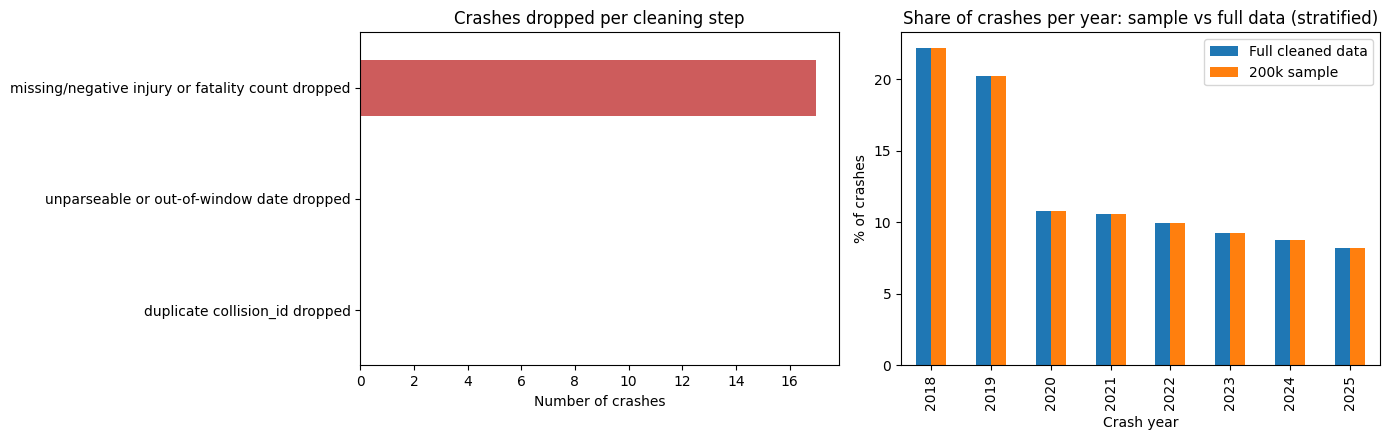

In [12]:
# ---- transport_clean.csv: crash-level cleaning (input: df from the ZIP-recovery cell) ----
VALID_BOROUGHS = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]
NYC_LAT, NYC_LON = (40.4, 41.0), (-74.3, -73.6)
SAMPLE_SIZE = 200_000
cleaning_log = {}

tc = df.copy()
cleaning_log["rows in (after ZIP recovery)"] = len(tc)

# 1. Duplicates: collision_id is the primary key of the crash dataset
n = len(tc); tc = tc.drop_duplicates(subset="collision_id", keep="first")
cleaning_log["duplicate collision_id dropped"] = n - len(tc)

# 2. Dates: must parse and fall inside the 2018-2025 analysis window
tc["crash_date"] = pd.to_datetime(tc["crash_date"], errors="coerce")
bad_date = ~tc["crash_date"].between("2018-01-01", "2025-12-31")
cleaning_log["unparseable or out-of-window date dropped"] = int(bad_date.sum())
tc = tc[~bad_date].copy()

# 3. Hour from crash_time ("9:35", "14:05"); invalid hours stay missing (hour charts skip them)
tc["crash_hour"] = pd.to_numeric(tc["crash_time"].astype("string").str.split(":").str[0], errors="coerce")
tc.loc[~tc["crash_hour"].between(0, 23), "crash_hour"] = np.nan
tc["crash_hour"] = tc["crash_hour"].astype("Int64")
cleaning_log["missing/invalid hour (kept, hour NaN)"] = int(tc["crash_hour"].isna().sum())

# 4. Coordinates outside NYC (including the 0,0 placeholder) -> missing; ZIP/borough are kept
bad_xy = ~(tc["latitude"].between(*NYC_LAT) & tc["longitude"].between(*NYC_LON)) & tc["latitude"].notna()
tc.loc[bad_xy, ["latitude", "longitude"]] = np.nan
cleaning_log["coordinates outside NYC set to NaN"] = int(bad_xy.sum())

# 5. Standard column names and numeric injury/fatality counts
tc = tc.rename(columns={"number_of_persons_injured": "persons_injured",
                        "number_of_persons_killed": "persons_killed",
                        "number_of_pedestrians_injured": "pedestrians_injured",
                        "number_of_cyclist_injured": "cyclists_injured",
                        "number_of_motorist_injured": "motorists_injured"})
count_cols = ["persons_injured", "persons_killed", "pedestrians_injured", "cyclists_injured", "motorists_injured"]
tc[count_cols] = tc[count_cols].apply(pd.to_numeric, errors="coerce")

# Missing or negative counts cannot be imputed honestly (0 would invent "no injuries"), so drop: very few rows
bad_counts = tc[count_cols].isna().any(axis=1) | (tc[count_cols] < 0).any(axis=1)
cleaning_log["missing/negative injury or fatality count dropped"] = int(bad_counts.sum())
tc = tc[~bad_counts].copy()
tc[count_cols] = tc[count_cols].astype(int)

# Outliers: counts are zero-inflated (Q3 = 0), so IQR would flag every injury. Domain rule instead:
# more than 30 people hurt in one crash is plausible (bus) but rare -> kept and flagged, not dropped
tc["injury_outlier"] = tc["persons_injured"] > 30
cleaning_log["injury outliers flagged (kept)"] = int(tc["injury_outlier"].sum())
cleaning_log["persons_injured != ped+cyc+motorist (kept)"] = int(
    (tc["persons_injured"] != tc[["pedestrians_injured", "cyclists_injured", "motorists_injured"]].sum(axis=1)).sum())

# 6. Borough: uppercase, only the five valid values
tc["borough"] = tc["borough"].astype("string").str.strip().str.upper()
tc.loc[~tc["borough"].isin(VALID_BOROUGHS), "borough"] = pd.NA
cleaning_log["borough still missing (kept)"] = int(tc["borough"].isna().sum())

# 7. Contributing factor (vehicle 1 only was downloaded): fix case, typos, numeric junk
factor_raw = tc["contributing_factor_vehicle_1"].astype("string").str.strip()
before_distinct = factor_raw.nunique()
key = factor_raw.str.lower()
key = key.where(~key.str.fullmatch(r"\d+").fillna(False))        # "1", "80" are data-entry junk
key = key.replace({"illnes": "illness"})                           # known typo in the source
# canonical spelling = most common original spelling among rows that were NOT typo-corrected
clean_spelling = factor_raw.where(factor_raw.str.lower() == key)
spelling = (pd.DataFrame({"key": key, "orig": clean_spelling}).dropna()
              .groupby("key")["orig"].agg(lambda s: s.mode().iloc[0]))
tc["top_contributing_factor"] = key.map(spelling).fillna(key.str.capitalize()).fillna("Unspecified")
cleaning_log["factor categories before -> after"] = f"{before_distinct} -> {tc['top_contributing_factor'].nunique()}"

# 8. Time columns
tc["crash_year"] = tc["crash_date"].dt.year
tc["crash_month"] = tc["crash_date"].dt.month
tc["crash_weekday"] = tc["crash_date"].dt.day_name()
tc["crash_date"] = tc["crash_date"].dt.date

out_cols = ["collision_id", "crash_date", "crash_year", "crash_month", "crash_hour", "crash_weekday",
            "borough", "zip_code", "zip_recovered", "latitude", "longitude", "persons_injured",
            "persons_killed", "pedestrians_injured", "cyclists_injured", "motorists_injured",
            "top_contributing_factor", "injury_outlier"]
tc = tc[out_cols]
cleaning_log["rows after cleaning"] = len(tc)

# 9. Sample for crash-level charts: random, proportional within each year (stratified by year).
# Exact ZIP x year totals use ALL crashes (zip_year_full), never this sample.
fraction = min(1.0, SAMPLE_SIZE / len(tc))
transport_clean = (tc.groupby("crash_year", group_keys=False)
                     .sample(frac=fraction, random_state=42)
                     .sort_values(["crash_date", "collision_id"]).reset_index(drop=True))
cleaning_log["rows in transport_clean.csv (stratified sample)"] = len(transport_clean)

for folder in SAVE_DIRS:
    transport_clean.to_csv(f"{folder}/transport_clean.csv", index=False)

print("Cleaning log:")
for step, value in cleaning_log.items():
    print(f"  {step}: {value:,}" if isinstance(value, int) else f"  {step}: {value}")
print("\nzip_code dtype:", transport_clean["zip_code"].dtype, "| ZIP missing:",
      f"{transport_clean['zip_code'].isna().mean() * 100:.1f}%")
display(transport_clean.head())

# Validation visuals: what each step removed, and sample vs full crashes per year
import matplotlib.pyplot as plt
steps = {k: v for k, v in cleaning_log.items() if isinstance(v, int) and "dropped" in k}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pd.Series(steps).plot.barh(ax=axes[0], color="indianred")
axes[0].set_title("Crashes dropped per cleaning step"); axes[0].set_xlabel("Number of crashes")
year_check = pd.DataFrame({"Full cleaned data": tc["crash_year"].value_counts(normalize=True).sort_index(),
                           "200k sample": transport_clean["crash_year"].value_counts(normalize=True).sort_index()})
(year_check * 100).plot.bar(ax=axes[1])
axes[1].set_title("Share of crashes per year: sample vs full data (stratified)")
axes[1].set_ylabel("% of crashes"); axes[1].set_xlabel("Crash year")
plt.tight_layout(); plt.show()

In [13]:
# ---- crashes_enriched.csv: transport_clean + the housing_group of each crash's ZIP ----
zip_to_group = merged.drop_duplicates("zip_code").set_index("zip_code")["housing_group"]

crashes_enriched = transport_clean.copy()
mapped = crashes_enriched["zip_code"].map(zip_to_group)
# crash without a ZIP -> "No ZIP" (unknown, not "no housing"); ZIP with no completed housing -> "None"
crashes_enriched["housing_group"] = np.where(crashes_enriched["zip_code"].isna(), "No ZIP", mapped.fillna("None"))

for folder in SAVE_DIRS:
    crashes_enriched.to_csv(f"{folder}/crashes_enriched.csv", index=False)

print("Rows:", len(crashes_enriched), "| columns:", crashes_enriched.shape[1])
print(crashes_enriched["housing_group"].value_counts(dropna=False))
display(crashes_enriched.head())

Rows: 199999 | columns: 19
housing_group
High      69984
Medium    52181
Low       46501
None      16542
No ZIP    14791
Name: count, dtype: int64


,collision_id,crash_date,crash_year,crash_month,crash_hour,crash_weekday,borough,zip_code,zip_recovered,latitude,longitude,persons_injured,persons_killed,pedestrians_injured,cyclists_injured,motorists_injured,top_contributing_factor,injury_outlier,housing_group
0,04dbc0c18ff7d6c043b9c62d98571f29,2018-01-01,2018,1,3,Monday,BRONX,10459,False,40.826786,-73.892944,1,0,0,0,1,Following Too Closely,False,High
1,0656ccc83d1d93dec6f2a5a98dde2129,2018-01-01,2018,1,17,Monday,QUEENS,11370,True,40.766685,-73.892136,0,0,0,0,0,Following Too Closely,False,Low
2,076873dfb44dd1c07f0dcfffd7f770a2,2018-01-01,2018,1,4,Monday,MANHATTAN,10012,True,40.725430,-73.996780,0,0,0,0,0,Driver Inattention/Distraction,False,Low
3,0775f38f80778f4c148219f0b00cfe2a,2018-01-01,2018,1,1,Monday,MANHATTAN,10031,False,40.817593,-73.953190,0,0,0,0,0,Failure to Keep Right,False,High
4,09e902ae61350c87b2e3ea964f2a13da,2018-01-01,2018,1,18,Monday,QUEENS,11372,False,40.749060,-73.890830,0,0,0,0,0,Unspecified,False,Low


### Summary of integration and cleaning results

In [14]:
from IPython.display import Markdown
status = merged_proto["match_status"].value_counts()
group_counts = merged.drop_duplicates("zip_code")["housing_group"].value_counts()
Markdown(f"""
### Integration and cleaning summary (generated from the data above)

- **ZIP x year table:** {len(merged):,} ZIP-years across {merged["zip_code"].nunique()} ZIPs;
  {status.get("both", 0):,} have both crashes and completed housing, {status.get("crash_only", 0):,} have crashes only,
  {status.get("housing_only", 0):,} have housing only.
- **Totals preserved by the join:** {int(merged["total_units"].sum()):,} housing units and {int(merged["crash_count"].sum()):,} crashes (2018-2025, crashes with a ZIP only).
- **Crash ZIPs:** {int(df["zip_recovered"].sum()):,} missing ZIPs were recovered by nearest-neighbour matching;
  {int(df["zip_code"].isna().sum()):,} crashes ({df["zip_code"].isna().mean() * 100:.1f}%) still have no ZIP and appear only in the borough-level table.
- **Housing groups (ZIPs):** High {group_counts.get("High", 0)}, Medium {group_counts.get("Medium", 0)}, Low {group_counts.get("Low", 0)}, None {group_counts.get("None", 0)}.
- **transport_clean.csv:** {cleaning_log["rows after cleaning"]:,} crashes after cleaning, {len(transport_clean):,} in the stratified sample.
- **crashes_enriched.csv:** {len(crashes_enriched):,} rows with each crash's ZIP housing group.
""")


### Integration and cleaning summary (generated from the data above)

- **ZIP x year table:** 1,683 ZIP-years across 228 ZIPs;
  718 have both crashes and completed housing, 965 have crashes only,
  0 have housing only.
- **Totals preserved by the join:** 242,247 housing units and 966,552 crashes (2018-2025, crashes with a ZIP only).
- **Crash ZIPs:** 266,590 missing ZIPs were recovered by nearest-neighbour matching;
  77,351 crashes (7.4%) still have no ZIP and appear only in the borough-level table.
- **Housing groups (ZIPs):** High 48, Medium 48, Low 48, None 84.
- **transport_clean.csv:** 1,043,886 crashes after cleaning, 199,999 in the stratified sample.
- **crashes_enriched.csv:** 199,999 rows with each crash's ZIP housing group.


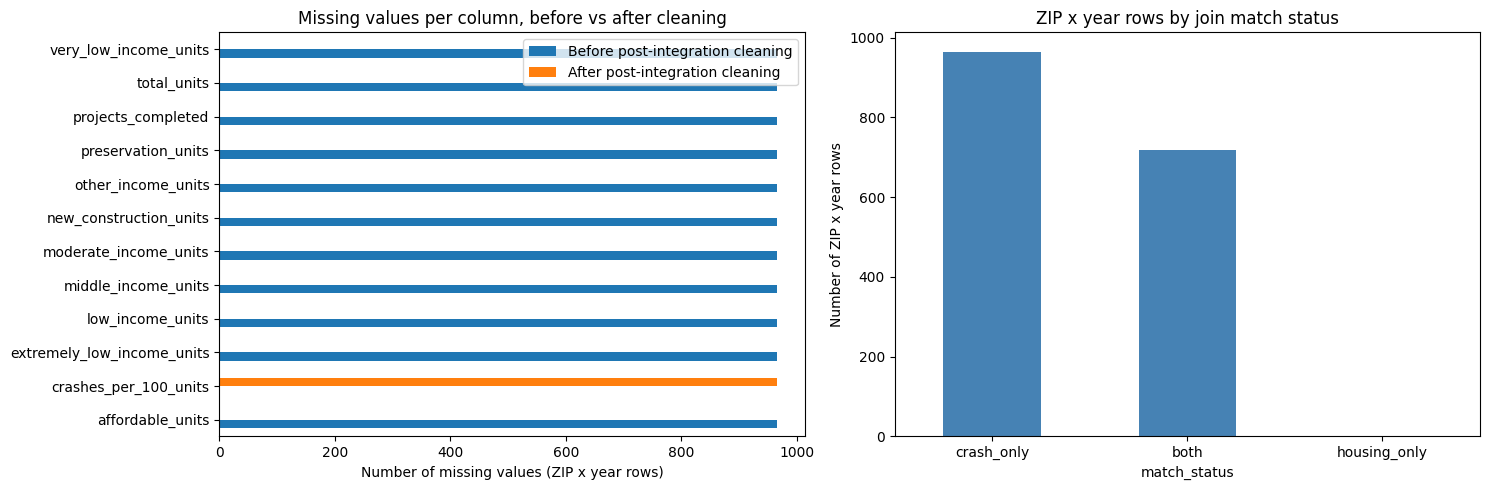

In [15]:
import matplotlib.pyplot as plt

cols_to_show = merged_proto.isna().sum()[lambda s: s > 0].index.union(
               merged.isna().sum()[lambda s: s > 0].index)
compare = pd.DataFrame({
    "Before post-integration cleaning": merged_proto.isna().sum().reindex(cols_to_show).fillna(0),
    "After post-integration cleaning": merged.isna().sum().reindex(cols_to_show).fillna(0)})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
compare.plot.barh(ax=axes[0])
axes[0].set_title("Missing values per column, before vs after cleaning")
axes[0].set_xlabel("Number of missing values (ZIP x year rows)")

merged_proto["match_status"].value_counts().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("ZIP x year rows by join match status")
axes[1].set_ylabel("Number of ZIP x year rows")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
%%writefile charts_member1.py
"""Member 1 charts (RQ1, RQ2). Each function takes already-filtered DataFrames and returns a Plotly figure."""
import numpy as np
import plotly.graph_objects as go
import plotly.express as px


def _empty_figure(message):
    fig = go.Figure()
    fig.add_annotation(text=message, showarrow=False, font=dict(size=16))
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    return fig


def fig_rq1(df_filtered):
    """RQ1: do ZIP-years with more completed affordable units also record more crashes?
    Input: filtered merged_zip_year DataFrame."""
    data = df_filtered[df_filtered["affordable_units"] > 0]
    if data.empty:
        return _empty_figure("No ZIP-years with completed affordable housing for these filters")

    fig = px.scatter(
        data, x="affordable_units", y="crash_count", color="borough", log_x=True,
        opacity=0.7, template="plotly_white",
        hover_data={"zip_code": True, "year": True, "total_units": True, "injuries_per_crash": True},
        labels={"affordable_units": "Affordable units completed in the ZIP that year (log scale)",
                "crash_count": "Crashes in the ZIP that year", "borough": "Borough"},
        title="Affordable housing completed vs. crashes, by ZIP code and year")
    fig.update_xaxes(tickvals=[1, 10, 100, 1000, 10000],
                     ticktext=["1", "10", "100", "1,000", "10,000"])

    # Trend line fitted on log10(units) vs crashes (numpy only, no extra dependency)
    x = data["affordable_units"].to_numpy(dtype=float)
    y = data["crash_count"].to_numpy(dtype=float)
    if len(data) >= 3 and x.min() != x.max():
        slope, intercept = np.polyfit(np.log10(x), y, 1)
        xs = np.linspace(x.min(), x.max(), 100)
        fig.add_trace(go.Scatter(x=xs, y=slope * np.log10(xs) + intercept, mode="lines",
                                 name="Trend (all ZIP-years)", line=dict(color="black", dash="dash")))
    return fig


def fig_rq2(housing_points, crash_points, max_crash_points=40000):
    """RQ2: where do affordable housing buildings overlap with crash hotspots?
    housing_points needs: latitude, longitude, total_units, zip_code, completion_year
    crash_points needs: latitude, longitude"""
    housing = housing_points.dropna(subset=["latitude", "longitude"])
    crashes = crash_points.dropna(subset=["latitude", "longitude"])
    if housing.empty and crashes.empty:
        return _empty_figure("No locations to show for these filters")
    if len(crashes) > max_crash_points:
        crashes = crashes.sample(max_crash_points, random_state=42)

    fig = go.Figure()
    fig.add_trace(go.Densitymapbox(
        lat=crashes["latitude"], lon=crashes["longitude"], radius=10,
        colorscale="YlOrRd", opacity=0.7, showscale=False, name="Crash density"))
    fig.add_trace(go.Scattermapbox(
        lat=housing["latitude"], lon=housing["longitude"], mode="markers",
        marker=dict(size=np.clip(np.sqrt(housing["total_units"].fillna(1)), 3, 12),
                    color="royalblue", opacity=0.65),
        text=("ZIP " + housing["zip_code"].astype(str) + " | " + housing["total_units"].astype(str)
              + " units | completed " + housing["completion_year"].astype(str)),
        hoverinfo="text", name="Affordable housing buildings"))
    fig.update_layout(
        title="Affordable housing buildings over crash density",
        # white-bg + free USGS tiles: no API key needed, works on the deployed site
        mapbox=dict(style="white-bg",
                    layers=[dict(below="traces", sourcetype="raster",
                                 source=["https://basemap.nationalmap.gov/arcgis/rest/services/USGSTopo/MapServer/tile/{z}/{y}/{x}"])],
                    center=dict(lat=40.71, lon=-73.97), zoom=9.3),
        margin=dict(l=0, r=0, t=40, b=0), legend=dict(x=0.01, y=0.99))
    return fig

Writing charts_member1.py


In [17]:
import importlib
import charts_member1
importlib.reload(charts_member1)

charts_member1.fig_rq1(merged).show()
charts_member1.fig_rq2(housing, df).show()

## Prompts used

All prompts were sent to Claude (Anthropic). For each step, we record what we verified or decided ourselves.

### 1. Project planning and team split
- **Prompt:** Attached the Dataset Catalog and Milestone 1 PDFs. "We are 5 members. Split the work evenly and tell me what each member does, in detail."

### 2. Dataset selection
- **Prompt:** "Create a step-by-step guide for my part and work through it slowly." Then pasted the Colab output back.

### 3. Missing-value check on join fields
- **Prompt:** Pasted the missing-value and per-year output. Asked whether to stop a slow query.


### 4. Full crash download and ZIP recovery
- **Prompt:** "Go ahead with the choices" (analysis window 2018-2025, recover missing ZIPs).
### 5. Integration and post-integration cleaning
- **Prompt:** Pasted the housing and merge outputs and asked for the next steps.

### 6. Final integration, housing verification, transport cleaning, enriched crashes
- **Prompt:** "Do the transport_clean.csv and redo the house cleaning to make sure everything is right then do crashes_enriched.csv." We ran the generated cells on the full data and checked the printed audit tables ourselves.
### 7. Review of the notebook and website against the project PDF
- **Prompt:** Attached the final notebook, the PDFs and screenshots of the website and asked what is missing or should be added.

### 8. EDA and housing cleaning
- **Prompt:** Asked what to add for the EDA of both datasets and for the housing cleaning. We ran the generated cells and pasted the printed output back to write the findings.

### 9. Website: search, filters, charts and story
- **Prompt:** Asked for a free-text search, housing and transport category filters, the remaining charts and a story section. We checked the live site with screenshots and then asked whether everything on it was necessary, which removed the repeated text.